# Hospital Readmissions: Exploratory and Statistical Analysis

**Data:** CMS Hospital Readmissions Reduction Program (HRRP), FY 2026 program year. Performance period
**1 Jul 2021 – 30 Jun 2024**. Joined to the FY 2026 HRRP Supplemental File (payment factors, penalty
indicators, dual-eligible proportion), Hospital General Information, and the FY 2026 IPPS Impact File.
See `docs/data_sources.md`.

**How to read this notebook**
* The unit of analysis is a **hospital** (or a hospital × clinical measure). Nothing here describes individual patients.
* Every result is an **association**. Hospital characteristics are not randomly assigned, so differences
  can reflect confounding (case mix, market, size), not causation.
* The **excess readmission ratio (ERR)** = predicted ÷ expected readmission rate, both risk-adjusted by CMS.
  ERR > 1 means more readmissions than an average hospital with the same patients would be expected to have.
* Run `python -m src.data_ingestion` and `python -m src.data_cleaning` first.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import statistical_analysis as sa, visualizations as viz
from src.data_cleaning import MEASURE_LABELS

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
viz.set_style()
PROC, TABLES = ROOT / "data" / "processed", ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
SHORT = {"AMI": "AMI", "CABG": "CABG", "COPD": "COPD", "HF": "Heart failure", "HIP_KNEE": "Hip/knee", "PN": "Pneumonia"}

mf  = pd.read_csv(PROC / "measure_fact.csv", dtype={"FACILITY_ID": str}, parse_dates=["START_DATE", "END_DATE"])
dim = pd.read_csv(PROC / "hospital_dim.csv", dtype={"FACILITY_ID": str})
df  = sa.analysis_frame(mf, dim)                    # ANALYZABLE hospital x measure rows + attributes
supp = dim[dim["IN_SUPPLEMENTAL"]].copy()           # hospitals with an official payment factor

## 1. Dataset dimensions, types and missing values

In [2]:
print("measure_fact:", mf.shape, "| hospital_dim:", dim.shape)
print("Reporting periods:", mf.groupby(["START_DATE", "END_DATE"]).size().to_dict())
print(mf["RECORD_STATUS"].value_counts().to_string())
mf.dtypes.to_frame("dtype").T

measure_fact: (18330, 20) | hospital_dim: (3055, 27)
Reporting periods: {(Timestamp('2021-07-01 00:00:00'), Timestamp('2024-06-30 00:00:00')): 18330}
RECORD_STATUS
ANALYZABLE         11720
EXCLUDED_NO_ERR     6610


,FACILITY_ID,FACILITY_NAME,STATE,MEASURE_CODE,MEASURE_NAME,NUMBER_OF_DISCHARGES,FOOTNOTE,EXCESS_READMISSION_RATIO,PREDICTED_READMISSION_RATE,EXPECTED_READMISSION_RATE,NUMBER_OF_READMISSIONS,READMISSIONS_SUPPRESSED,START_DATE,END_DATE,RECORD_STATUS,ELIGIBLE_DISCHARGES,PEER_GROUP_MEDIAN_ERR,PENALTY_INDICATOR,DRG_PAYMENT_RATIO,EST_EXCESS_READMISSIONS
dtype,str,str,str,str,str,float64,float64,float64,float64,float64,float64,bool,datetime64[us],datetime64[us],str,float64,float64,str,float64,float64


In [3]:
missing = pd.DataFrame({"missing": mf.isna().sum(), "pct": 100 * mf.isna().mean()}).query("missing > 0")
missing.sort_values("pct", ascending=False)

,missing,pct
FOOTNOTE,11343,61.8822
NUMBER_OF_READMISSIONS,10293,56.1538
NUMBER_OF_DISCHARGES,10088,55.0355
EST_EXCESS_READMISSIONS,7000,38.1888
EXCESS_READMISSION_RATIO,6610,36.0611
EXPECTED_READMISSION_RATE,6610,36.0611
PREDICTED_READMISSION_RATE,6610,36.0611
ELIGIBLE_DISCHARGES,3877,21.1511
DRG_PAYMENT_RATIO,3689,20.1255
PENALTY_INDICATOR,708,3.8625


In [4]:
# Why is ERR missing? CMS footnote codes on rows with no ERR.
mf.loc[mf.EXCESS_READMISSION_RATIO.isna(), "FOOTNOTE"].value_counts(dropna=False).rename("rows").to_frame()

,rows
FOOTNOTE,
5.0000,3255
1.0000,3150
7.0000,205


**Interpretation.** There is one reporting period, so trend analysis is **not possible with the current
files** (it would need archived prior-year HRRP files). ERR is missing for 6,610 of 18,330 hospital ×
measure rows. CMS footnotes explain all of these, mostly *1* (too few cases to report) and *5* (no data /
not applicable, e.g. hospitals that do not perform CABG). These rows are excluded, not imputed. Missing
`ELIGIBLE_DISCHARGES` and `PENALTY_INDICATOR` come from hospitals that are not in the Supplemental file
(mainly Maryland, which is exempt from HRRP payment adjustment).

Missing hospital attributes (teaching status, urban/rural, bed size: 41 hospitals not in the Impact File)
are handled by **complete-case analysis within each test**. Sample sizes are reported with each test.

## 2. Readmission measure distributions

In [5]:
desc = df.groupby("MEASURE_CODE")["EXCESS_READMISSION_RATIO"].describe()
desc["iqr"] = desc["75%"] - desc["25%"]
desc.to_csv(TABLES / "err_summary_by_measure.csv"); desc

,count,mean,std,min,25%,50%,75%,max,iqr
MEASURE_CODE,,,,,,,,,
AMI,"1,736.0000",1.0018,0.0668,0.6839,0.9608,0.9994,1.0422,1.2639,0.0814
CABG,878.0000,1.0018,0.0966,0.7434,0.9378,1.0000,1.0622,1.4237,0.1243
COPD,"2,323.0000",1.0011,0.0460,0.8681,0.9707,0.9969,1.0281,1.2545,0.0574
HF,"2,621.0000",1.0014,0.0650,0.7137,0.9606,0.9983,1.0414,1.3606,0.0808
HIP_KNEE,"1,447.0000",1.0040,0.1557,0.4698,0.9001,0.9916,1.0888,1.6297,0.1887
PN,"2,715.0000",1.0015,0.0663,0.7967,0.9596,0.9955,1.0388,1.4255,0.0792


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


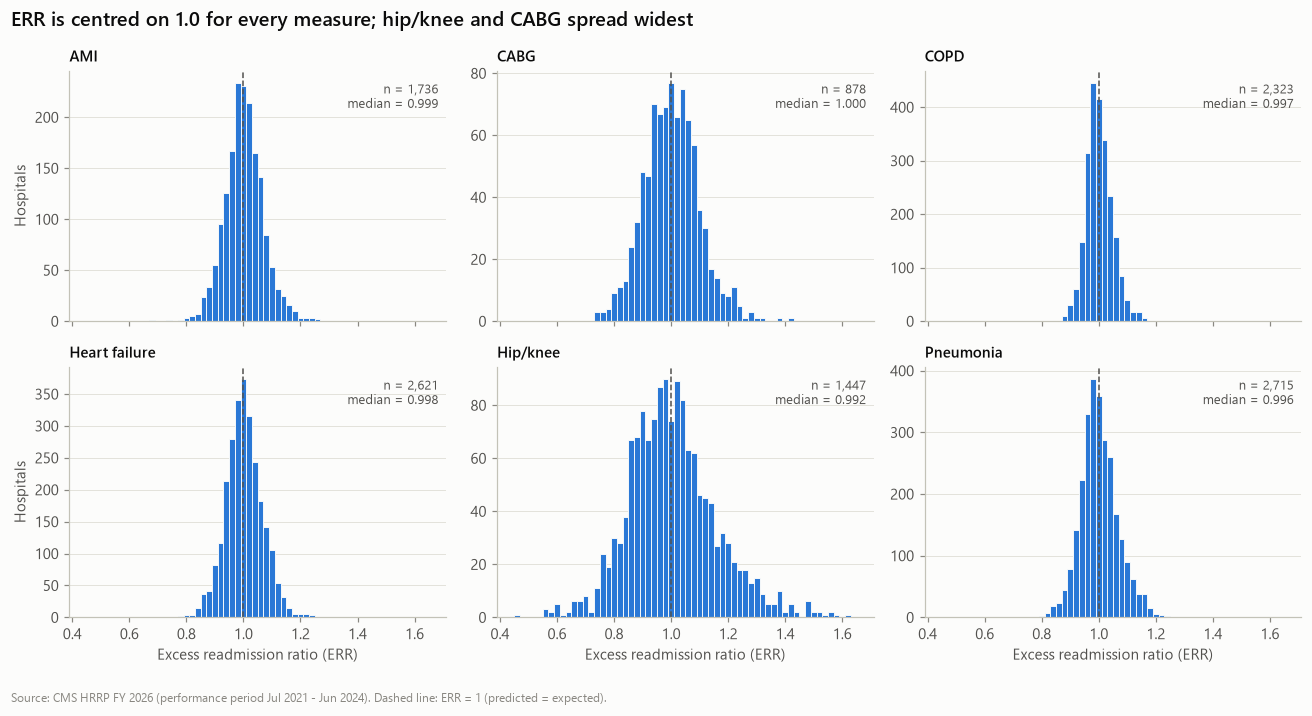

In [6]:
viz.err_distributions(df, SHORT, title="ERR is centred on 1.0 for every measure; hip/knee and CABG spread widest")
plt.show()

**Interpretation.** ERR is centred on 1.0 for every measure. That is by design: the expected rate is
the rate of an *average* hospital with the same case mix. So a typical ERR of ~1.00 is not evidence of
good or bad national performance. Hip/knee replacement (SD 0.156) and CABG (SD 0.097) vary most between
hospitals. Distributions are close to symmetric (skew 0.1–0.5), which supports comparing means with
Welch's t-test.

## 3. Outlier investigation

In [7]:
def iqr_flags(s):
    q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return (s < q1 - k) | (s > q3 + k)
df["ERR_OUTLIER"] = df.groupby("MEASURE_CODE")["EXCESS_READMISSION_RATIO"].transform(iqr_flags)
out = df.groupby("MEASURE_CODE").agg(rows=("ERR_OUTLIER", "size"), outliers=("ERR_OUTLIER", "sum"),
                                     high=("EXCESS_READMISSION_RATIO", lambda s: int((iqr_flags(s) & (s > 1)).sum())))
out["pct"] = 100 * out["outliers"] / out["rows"]; out

,rows,outliers,high,pct
MEASURE_CODE,,,,
AMI,1736,39,26,2.2465
CABG,878,11,8,1.2528
COPD,2323,44,40,1.8941
HF,2621,41,24,1.5643
HIP_KNEE,1447,44,33,3.0408
PN,2715,71,54,2.6151


In [8]:
# Are outliers concentrated in small-volume hospitals? (CMS shrinks small-hospital ERRs toward 1.)
df.groupby("ERR_OUTLIER")["ELIGIBLE_DISCHARGES"].median().rename("median eligible discharges").to_frame()

,median eligible discharges
ERR_OUTLIER,
False,128.0000
True,270.0000


**Interpretation.** Outliers are flagged with the 1.5 × IQR rule within each measure. They are **kept**:
they are valid CMS-published values, not data errors, and they matter most for improvement work.
Outlier hospitals have higher median discharge volumes. That is consistent with CMS's hierarchical
model pulling small-hospital ERRs toward 1.0, so extreme ERRs are more likely to show up in larger
hospitals. Hospital-level outlier lists are produced in the SQL ranking scripts, not as a "worst
hospitals" claim here.

## 4. Hospital characteristics: who is in the data?

In [9]:
print("Hospital Type among HRRP hospitals:", dim["HOSPITAL_TYPE"].value_counts(dropna=False).to_dict())
for c in ["TEACHING_STATUS", "OWNERSHIP_CONTROL", "URBAN_RURAL", "BED_SIZE_GROUP", "CENSUS_REGION"]:
    print(f"{c}:", dim[c].value_counts(dropna=False).to_dict())

Hospital Type among HRRP hospitals: {'Acute Care Hospitals': 3035, nan: 20}
TEACHING_STATUS: {'Non-teaching': 1738, 'Teaching': 1276, nan: 41}
OWNERSHIP_CONTROL: {'Voluntary': 1908, 'Proprietary': 682, 'Government': 424, nan: 41}
URBAN_RURAL: {'Other urban': 1226, 'Large urban': 1111, 'Rural': 677, nan: 41}
BED_SIZE_GROUP: {'100-299 beds': 1229, '<100 beds': 1127, '300+ beds': 658, nan: 41}
CENSUS_REGION: {'South Atlantic': 540, 'West South Central': 471, 'East North Central': 468, 'Pacific': 373, 'Middle Atlantic': 319, 'East South Central': 264, 'West North Central': 232, 'Mountain': 226, 'New England': 121, nan: 41}


**Hospital type cannot be used as a comparison group.** Every HRRP hospital that matches General
Information is an *Acute Care Hospital*, because the program only covers subsection (d) acute hospitals.
The comparisons below use the characteristics that do vary: teaching status (proxy: resident-to-bed
ratio > 0), ownership, urban/rural location, bed size, Census division and dual-eligible peer group.

## 5. Hypothesis tests

**Pre-specified approach** (decided before looking at p-values):
* Each test is run **within one clinical measure**, so each hospital contributes one value per test.
* Two groups: **Welch's t-test** (primary: near-symmetric data, large n, unequal variances allowed, see the
  Levene p-values) with **Mann–Whitney U** as a robustness check. Effect sizes: Hedges' *g* and rank-biserial *r*.
* k groups: **Welch's ANOVA** (primary) and **Kruskal–Wallis** (robustness). Effect size: ε² (≈0.01 small, ≈0.08 medium, ≈0.26 large).
* p-values are **Holm-adjusted across the six measures** in each family (`_holm` columns).
* Sensitivity: tests are repeated on hospitals with ≥100 eligible discharges, where ERRs are less shrunk toward 1.

With n in the thousands, tiny differences can be "significant". Read the **effect size and CI**, not only the p-value.

### H1. Teaching vs. non-teaching hospitals
* H₀: mean ERR is equal for teaching and non-teaching hospitals (for a given measure).
* H₁: mean ERR differs.

In [10]:
cols = ["MEASURE_CODE", "n_a", "n_b", "mean_a", "mean_b", "mean_diff", "ci95_low", "ci95_high",
        "welch_p_holm", "hedges_g", "mwu_p_holm", "rank_biserial", "levene_p"]
h1 = sa.by_measure(df, sa.compare_two_groups, value="EXCESS_READMISSION_RATIO",
                   group="TEACHING_STATUS", a="Teaching", b="Non-teaching")
h1.to_csv(TABLES / "h1_teaching_err.csv", index=False); h1[cols]

,MEASURE_CODE,n_a,n_b,mean_a,mean_b,mean_diff,ci95_low,ci95_high,welch_p_holm,hedges_g,mwu_p_holm,rank_biserial,levene_p
0,AMI,1031,704,1.0040,0.9984,0.0055,-0.0007,0.0118,0.4069,0.0829,0.2259,0.0587,0.0002
1,CABG,651,227,1.0012,1.0035,-0.0023,-0.0164,0.0118,1.0000,-0.0239,1.0000,-0.0340,0.5865
2,COPD,1151,1171,1.0032,0.9991,0.0041,0.0004,0.0078,0.1896,0.0893,0.2779,0.0457,0.0009
3,HF,1227,1393,1.0023,1.0007,0.0017,-0.0034,0.0067,1.0000,0.0256,1.0000,0.0173,0.0000
4,HIP_KNEE,759,687,1.0073,1.0005,0.0068,-0.0093,0.0228,1.0000,0.0433,1.0000,0.0186,0.0390
5,PN,1224,1489,1.0039,0.9995,0.0044,-0.0007,0.0095,0.4069,0.0669,0.2779,0.0427,0.0000


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


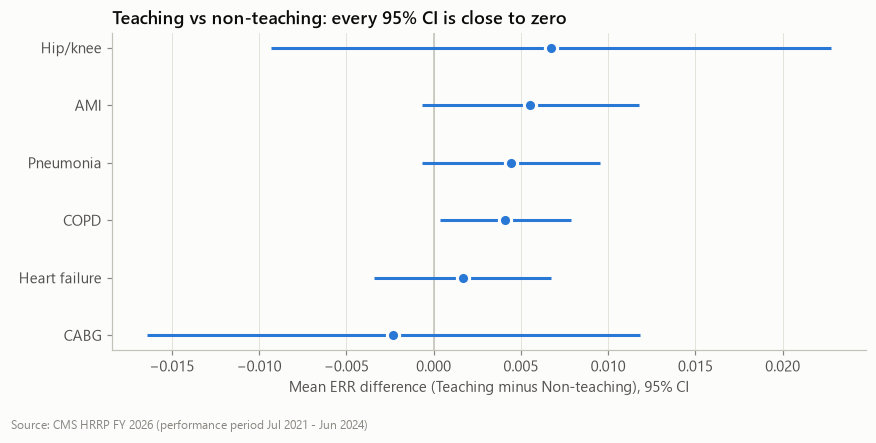

,MEASURE_CODE,n_a,n_b,mean_diff,welch_p_holm
0,AMI,734,314,0.0033,1.0000
1,CABG,282,63,0.0120,1.0000
2,COPD,630,340,0.0013,1.0000
3,HF,996,855,0.0029,1.0000
4,HIP_KNEE,307,217,0.0018,1.0000
5,PN,1034,1018,0.0008,1.0000


In [11]:
viz.group_mean_dotplot(h1, SHORT, "Teaching", "Non-teaching",
                       "Teaching vs non-teaching: every 95% CI is close to zero",
                       name="03_teaching_err_difference"); plt.show()
h1s = sa.by_measure(df[df.ELIGIBLE_DISCHARGES >= 100], sa.compare_two_groups, value="EXCESS_READMISSION_RATIO",
                    group="TEACHING_STATUS", a="Teaching", b="Non-teaching")
h1s[["MEASURE_CODE", "n_a", "n_b", "mean_diff", "welch_p_holm"]]

**Result.** After Holm correction, **no measure shows a statistically significant ERR difference** between
teaching and non-teaching hospitals (all adjusted p > 0.18). The effect sizes are negligible (|g| < 0.1),
and every CI lies within about ±0.02 of zero. The ≥100-discharge sensitivity analysis gives the same answer.
We do not reject H₀. Teaching status, as measured by this proxy, is not associated with meaningfully
different risk-adjusted readmission performance.

### H2. Ownership (government / proprietary / voluntary non-profit)
* H₀: mean ERR is equal across ownership types. H₁: at least one differs.

In [12]:
h2 = sa.by_measure(df, sa.compare_k_groups, value="EXCESS_READMISSION_RATIO", group="OWNERSHIP_CONTROL")
h2_view = pd.concat([h2[["MEASURE_CODE", "n", "welch_p_holm", "kruskal_p_holm", "epsilon_sq", "levene_p"]],
                     pd.DataFrame(h2["group_mean"].tolist()).add_prefix("mean_")], axis=1)
h2_view.to_csv(TABLES / "h2_ownership_err.csv", index=False); h2_view

,MEASURE_CODE,n,welch_p_holm,kruskal_p_holm,epsilon_sq,levene_p,mean_Government,mean_Proprietary,mean_Voluntary
0,AMI,1735,0.0000,0.0000,0.0178,0.3420,1.0082,1.0189,0.9960
1,CABG,878,0.0001,0.0000,0.0246,0.5743,1.0072,1.0327,0.9940
2,COPD,2322,0.4004,0.2417,0.0010,0.0018,1.0009,1.0044,1.0003
3,HF,2620,0.0000,0.0000,0.0177,0.0000,1.0070,1.0164,0.9961
4,HIP_KNEE,1446,0.4004,0.3853,0.0000,0.0997,0.9991,1.0169,1.0007
5,PN,2713,0.0000,0.0000,0.0099,0.0187,1.0000,1.0162,0.9976


In [13]:
# Post-hoc for heart failure (largest measure with a significant omnibus test): pairwise Welch, Holm-adjusted
sa.pairwise_posthoc(df[df.MEASURE_CODE == "HF"], "EXCESS_READMISSION_RATIO", "OWNERSHIP_CONTROL")[
    ["group_a", "group_b", "n_a", "n_b", "mean_diff", "ci95_low", "ci95_high", "welch_p_holm", "hedges_g"]]

,group_a,group_b,n_a,n_b,mean_diff,ci95_low,ci95_high,welch_p_holm,hedges_g
0,Government,Proprietary,344,500,-0.0095,-0.0174,-0.0016,0.0189,-0.1634
1,Government,Voluntary,344,1776,0.0108,0.0041,0.0176,0.0034,0.1646
2,Proprietary,Voluntary,500,1776,0.0203,0.0143,0.0264,0.0000,0.3090


**Result.** Ownership differences are significant for AMI, CABG, heart failure and pneumonia, but not COPD
or hip/knee. **Proprietary hospitals have the highest mean ERR** for those four measures. Effect sizes are
**small** (ε² ≤ 0.025): ownership explains at most ~2.5% of the variation in ERR ranks. The adjusted model
in §7 checks whether this survives once size, location and patient mix are controlled for.

### H3. Large urban vs. rural hospitals
* H₀: mean ERR is equal for large-urban and rural hospitals. H₁: it differs.

In [14]:
h3 = sa.by_measure(df, sa.compare_two_groups, value="EXCESS_READMISSION_RATIO",
                   group="URBAN_RURAL", a="Large urban", b="Rural")
h3.to_csv(TABLES / "h3_urban_rural_err.csv", index=False); display(h3[cols])
h3s = sa.by_measure(df[df.ELIGIBLE_DISCHARGES >= 100], sa.compare_two_groups, value="EXCESS_READMISSION_RATIO",
                    group="URBAN_RURAL", a="Large urban", b="Rural")
h3s[["MEASURE_CODE", "n_a", "n_b", "mean_diff", "ci95_low", "ci95_high", "welch_p_holm"]]

,MEASURE_CODE,n_a,n_b,mean_a,mean_b,mean_diff,ci95_low,ci95_high,welch_p_holm,hedges_g,mwu_p_holm,rank_biserial,levene_p
0,AMI,679,210,1.0104,0.9930,0.0174,0.0087,0.0261,0.0005,0.2778,0.0026,0.1556,0.0023
1,CABG,349,43,0.9962,1.0041,-0.0079,-0.0327,0.0169,0.5275,-0.0876,0.6880,-0.0376,0.1135
2,COPD,842,489,1.0060,0.9972,0.0088,0.0040,0.0136,0.0013,0.2022,0.0009,0.1227,0.1368
3,HF,946,585,1.0061,1.0017,0.0044,-0.0015,0.0103,0.2951,0.0722,0.3730,0.0401,0.0000
4,HIP_KNEE,570,202,1.0109,0.9898,0.0210,-0.0039,0.0460,0.2951,0.1271,0.3020,0.0777,0.0286
5,PN,964,639,1.0111,0.9908,0.0203,0.0141,0.0265,0.0000,0.3178,0.0000,0.1776,0.0008


,MEASURE_CODE,n_a,n_b,mean_diff,ci95_low,ci95_high,welch_p_holm
0,AMI,397,79,0.0293,0.0127,0.0458,0.0032
1,CABG,129,9,-0.0361,-0.0986,0.0264,0.8407
2,COPD,356,97,0.0001,-0.0129,0.0132,1.0000
3,HF,700,292,0.0018,-0.0068,0.0104,1.0000
4,HIP_KNEE,225,52,0.0372,-0.0214,0.0959,0.8407
5,PN,749,395,0.0195,0.0113,0.0278,0.0000


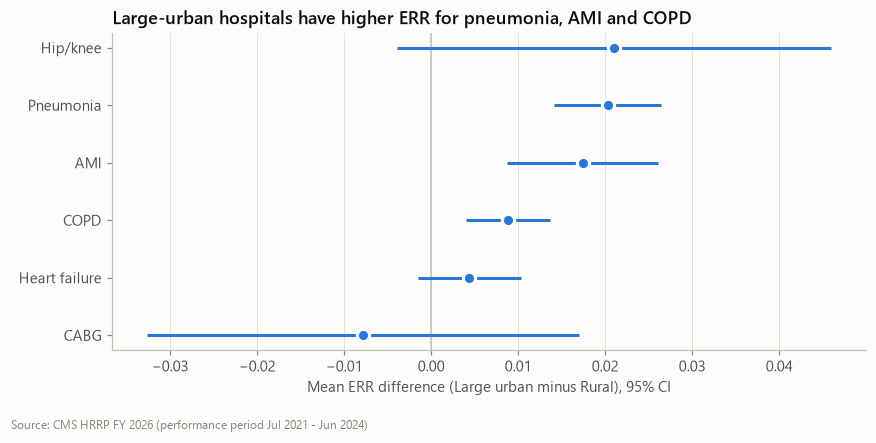

In [15]:
viz.group_mean_dotplot(h3, SHORT, "Large urban", "Rural",
                       "Large-urban hospitals have higher ERR for pneumonia, AMI and COPD",
                       name="04_urban_rural_err_difference"); plt.show()

**Result.** Large-urban hospitals have significantly higher ERR than rural hospitals for **pneumonia**
(+0.020, 95% CI 0.014–0.027), **AMI** (+0.017) and **COPD** (+0.009). Effect sizes are small to modest
(g ≈ 0.2–0.3). In the ≥100-discharge sensitivity analysis the pneumonia and AMI differences persist, but
COPD does not. So the COPD finding is less robust. Urban/rural status is entangled with size, teaching
status and patient mix (see §7).

### H4. Which hospitals receive a payment reduction?
`IS_PENALIZED` = official payment adjustment factor < 1.0 (from the CMS Supplemental File).
* H₀: the share of penalized hospitals is independent of the characteristic. H₁: it is not.
* Test: chi-square test of independence (all expected cell counts ≥ 90, so the approximation is valid). Effect size: Cramér's V.

In [16]:
rows = []
for g in ["TEACHING_STATUS", "OWNERSHIP_CONTROL", "URBAN_RURAL", "BED_SIZE_GROUP", "PEER_GROUP"]:
    c = sa.chi_square(supp, g, "IS_PENALIZED")
    share = (c["table"][True] / c["table"].sum(axis=1)).round(3).to_dict()
    k = sa.compare_k_groups(supp, "PAYMENT_REDUCTION_PCT", g)
    rows.append({"characteristic": g, "n": c["n"], "chi2": c["chi2"], "p": c["p"], "cramers_v": c["cramers_v"],
                 "min_expected": c["min_expected"], "share_penalized": share,
                 "mean_reduction_pct": {kk: round(v, 3) for kk, v in k["group_mean"].items()},
                 "kruskal_p_reduction": k["kruskal_p"], "eps2_reduction": k["epsilon_sq"]})
h4 = pd.DataFrame(rows); h4["p_holm"] = sa.multipletests(h4["p"], method="holm")[1]
h4.to_csv(TABLES / "h4_penalty_by_characteristic.csv", index=False); h4

,characteristic,n,chi2,p,cramers_v,min_expected,share_penalized,mean_reduction_pct,kruskal_p_reduction,eps2_reduction,p_holm
0,TEACHING_STATUS,2928,82.0832,0.0000,0.1674,269.6025,"{'Non-teaching': 0.726, 'Teaching': 0.865}","{'Non-teaching': 0.326, 'Teaching': 0.372}",0.0000,0.0135,0.0000
1,OWNERSHIP_CONTROL,2928,13.9835,0.0009,0.0691,89.6530,"{'Government': 0.751, 'Proprietary': 0.747, 'V...","{'Government': 0.268, 'Proprietary': 0.431, 'V...",0.0001,0.0061,0.0018
2,URBAN_RURAL,2928,7.8144,0.0201,0.0517,143.0587,"{'Large urban': 0.795, 'Other urban': 0.799, '...","{'Large urban': 0.355, 'Other urban': 0.365, '...",0.0006,0.0044,0.0201
3,BED_SIZE_GROUP,2928,263.7193,0.0000,0.3001,138.9836,"{'100-299 beds': 0.875, '300+ beds': 0.889, '<...","{'100-299 beds': 0.418, '300+ beds': 0.355, '<...",0.0000,0.0711,0.0000
4,PEER_GROUP,2937,46.0376,0.0000,0.1252,126.4811,"{1.0: 0.685, 2.0: 0.828, 3.0: 0.812, 4.0: 0.81...","{1.0: 0.349, 2.0: 0.366, 3.0: 0.344, 4.0: 0.33...",0.0021,0.0044,0.0000


In [17]:
# Mechanism check: how many measures can each hospital be penalized on (>= 25 eligible discharges)?
elig = mf[mf.ELIGIBLE_DISCHARGES >= 25].groupby("FACILITY_ID").size().rename("ELIGIBLE_MEASURES")
s2 = supp.merge(elig, on="FACILITY_ID", how="left").fillna({"ELIGIBLE_MEASURES": 0})
s2.groupby("BED_SIZE_GROUP").agg(hospitals=("FACILITY_ID", "size"), mean_eligible_measures=("ELIGIBLE_MEASURES", "mean"),
                                 share_penalized=("IS_PENALIZED", "mean"))

,hospitals,mean_eligible_measures,share_penalized
BED_SIZE_GROUP,,,
100-299 beds,1198,4.3848,0.8748
300+ beds,648,5.1821,0.8889
<100 beds,1082,2.5074,0.6248


**Result.** Bed size has the strongest association with being penalized (Cramér's V = 0.30).
62.5% of hospitals with fewer than 100 beds receive a reduction, against 87–89% of larger hospitals.
Teaching hospitals are also penalized more often (86.5% vs 72.6%, V = 0.17), **even though H1 found no
difference in their ERRs**.

A plausible mechanism is **eligibility**. A measure can only contribute to a penalty if the hospital has
≥25 eligible discharges for it. Smaller hospitals qualify on fewer measures (shown above), so they have
fewer chances to exceed a peer median. This is a feature of how the program calculates penalties, not
evidence that larger or teaching hospitals provide worse care.

### H5. Dual-eligible patient mix: performance vs. penalty
CMS sorts hospitals into five peer groups by the share of stays for patients dually eligible for Medicare
and full Medicaid, a socioeconomic proxy. Each hospital's ERR is compared with **its own peer group's median**.

In [18]:
hosp_err = df.groupby("FACILITY_ID")["EXCESS_READMISSION_RATIO"].mean().rename("MEAN_ERR")
hd = supp.merge(hosp_err, on="FACILITY_ID", how="left")
pg = hd.groupby("PEER_GROUP").agg(hospitals=("FACILITY_ID", "size"), dual_min=("DUAL_PROPORTION", "min"),
                                  dual_max=("DUAL_PROPORTION", "max"), mean_err=("MEAN_ERR", "mean"),
                                  penalized_share=("IS_PENALIZED", "mean"),
                                  mean_reduction_pct=("PAYMENT_REDUCTION_PCT", "mean")).reset_index()
pg.to_csv(TABLES / "h5_peer_groups.csv", index=False)
print("Kruskal-Wallis, mean ERR across peer groups:", sa.compare_k_groups(hd, "MEAN_ERR", "PEER_GROUP")["kruskal_p"])
print("Kruskal-Wallis, payment reduction across peer groups:", sa.compare_k_groups(hd, "PAYMENT_REDUCTION_PCT", "PEER_GROUP")["kruskal_p"])
pg

Kruskal-Wallis, mean ERR across peer groups: 6.639089302286622e-18
Kruskal-Wallis, payment reduction across peer groups: 0.0021409473384961636


,PEER_GROUP,hospitals,dual_min,dual_max,mean_err,penalized_share,mean_reduction_pct
0,1.0000,588,0.0000,0.1461,0.9841,0.6854,0.3488
1,2.0000,588,0.1461,0.1919,0.9976,0.8282,0.3656
2,3.0000,589,0.1919,0.2412,0.9974,0.8115,0.3435
3,4.0000,587,0.2414,0.3182,1.0024,0.8126,0.3344
4,5.0000,585,0.3182,0.9965,1.0167,0.7812,0.3305


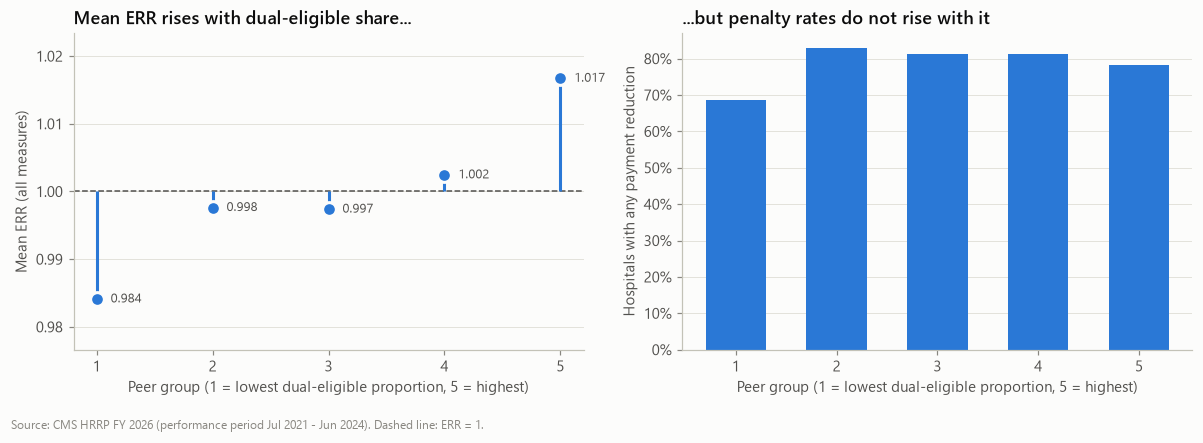

In [19]:
viz.peer_group_panels(pg, left_title="Mean ERR rises with dual-eligible share...",
                      right_title="...but penalty rates do not rise with it"); plt.show()

**Result.** Mean ERR increases steadily from peer group 1 (0.984) to peer group 5 (1.017): hospitals
serving more dual-eligible patients have more readmissions than CMS's risk model expects. But the share
of hospitals penalized does not rise with peer group, and the mean payment reduction is nearly flat
(0.33–0.37%; the Kruskal–Wallis test detects a difference, p = 0.002, but ε² = 0.004 is negligible, and
the mean falls slightly from group 2 to group 5). The lowest-dual group 1 is penalized least often. This is consistent with what the peer
grouping (introduced in FY 2019) is designed to do: hospitals are judged against peers with similar patient mix.

Readmission differences linked to social risk therefore **persist in the outcome data but are largely
neutralized in the penalty**. Leadership should not read a low penalty as proof of low readmission risk.

## 6. Correlation analysis (Spearman)

Spearman's ρ is used because several variables are skewed (beds, resident ratio) or ordinal (star rating),
and it is robust to outliers. Each correlation uses **pairwise-complete** hospitals (n per pair is saved to
`reports/tables/spearman_n.csv`).

**Redundancy warnings:**
* `PAYMENT_REDUCTION_PCT` is *computed from* the six ERRs, so its correlations with ERR are partly built in by construction.
* `OVERALL_RATING` (star rating) *includes* a readmission measure group, so it is not independent of ERR.
* `DUAL_PROPORTION` and `DSH_PATIENT_PCT` both measure low-income patient share. They overlap by design (ρ ≈ 0.68).

pairwise n ranges from 653 to 2,831


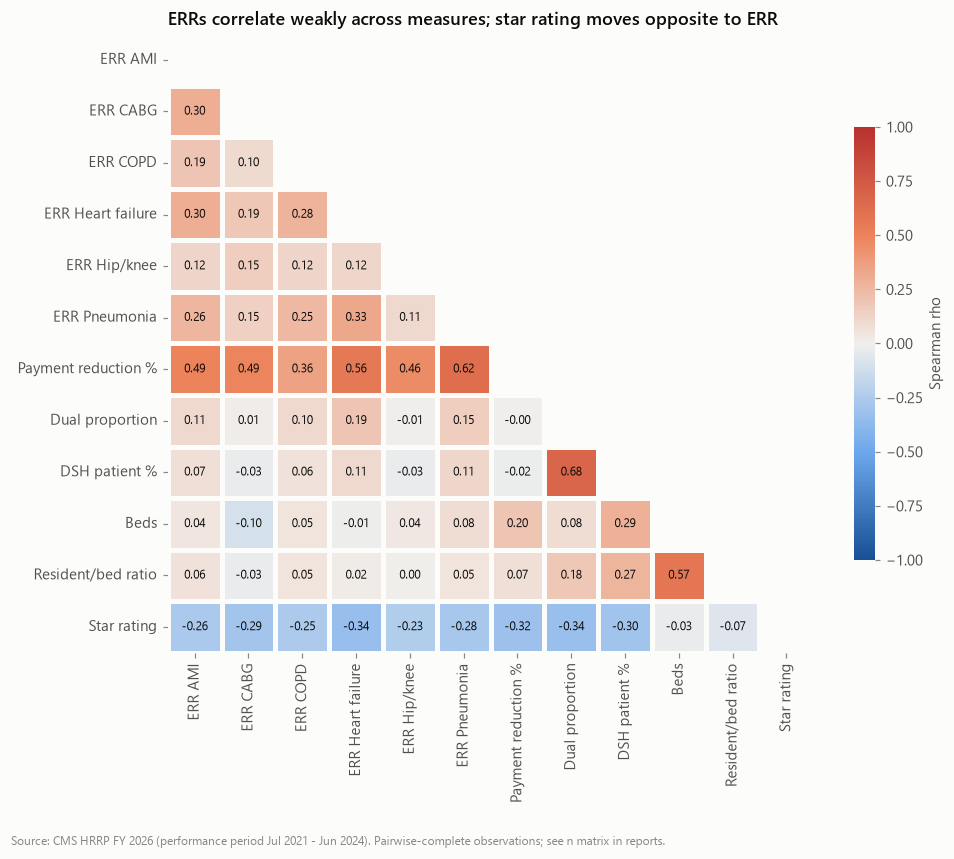

In [20]:
wide = df.pivot_table(index="FACILITY_ID", columns="MEASURE_CODE", values="EXCESS_READMISSION_RATIO").add_prefix("ERR_")
attrs = ["PAYMENT_REDUCTION_PCT", "DUAL_PROPORTION", "DSH_PATIENT_PCT", "BEDS", "RESIDENT_TO_BED_RATIO", "OVERALL_RATING"]
w = wide.merge(dim.set_index("FACILITY_ID")[attrs], left_index=True, right_index=True, how="left")
rho, pvals, n = sa.spearman_matrix(w, list(w.columns))
rho.to_csv(TABLES / "spearman_rho.csv"); pvals.to_csv(TABLES / "spearman_p.csv"); n.to_csv(TABLES / "spearman_n.csv")
print(f"pairwise n ranges from {n.values.min():,} to {n.values.max():,}")
LBL = {f"ERR_{k}": f"ERR {v}" for k, v in SHORT.items()} | {"PAYMENT_REDUCTION_PCT": "Payment reduction %",
       "DUAL_PROPORTION": "Dual proportion", "DSH_PATIENT_PCT": "DSH patient %", "BEDS": "Beds",
       "RESIDENT_TO_BED_RATIO": "Resident/bed ratio", "OVERALL_RATING": "Star rating"}
viz.corr_heatmap(rho, LBL, "ERRs correlate weakly across measures; star rating moves opposite to ERR"); plt.show()

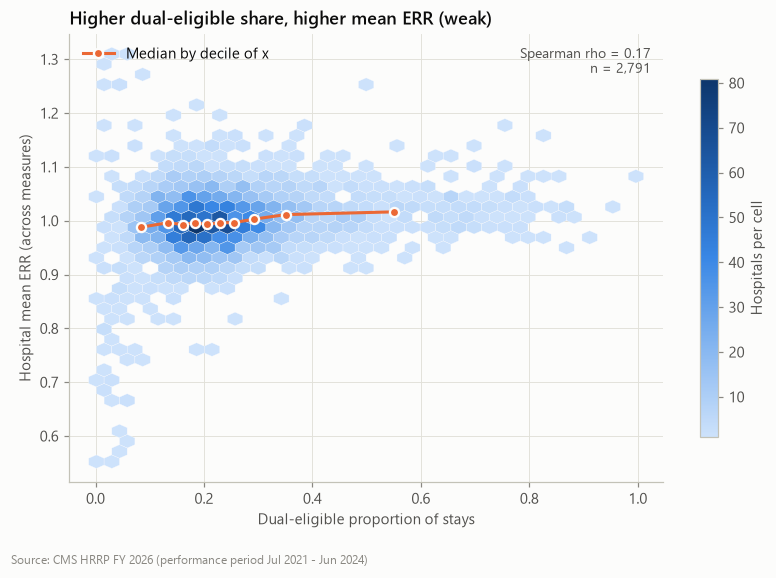

In [21]:
viz.hexbin_relationship(hd, "DUAL_PROPORTION", "MEAN_ERR", "Dual-eligible proportion of stays",
                        "Hospital mean ERR (across measures)", "Higher dual-eligible share, higher mean ERR (weak)",
                        name="07_dual_proportion_vs_mean_err",
                        rho=sa.spearman_matrix(hd, ["DUAL_PROPORTION", "MEAN_ERR"])[0].iloc[0, 1]); plt.show()

**Interpretation.**
* **ERRs across measures are weakly positively correlated** (ρ ≈ 0.10–0.33). The strongest pair is heart
  failure–pneumonia (0.33). A hospital that does poorly on one condition tends to do a little worse on
  others, which hints at hospital-wide factors such as discharge processes. But most variation is specific to each measure.
* **Star rating is negatively associated with every ERR** (ρ ≈ −0.23 to −0.34). This is partly redundant, as noted above.
* **Dual proportion has a weak positive association with ERR** (strongest for HF, ρ ≈ 0.19) but essentially
  **zero** correlation with payment reduction (ρ ≈ 0.00). This matches H5.
* **Beds and teaching intensity are essentially uncorrelated with ERR** (|ρ| ≤ 0.10).
None of these correlations imply causation.

## 7. Adjusting for observed confounders

The single-factor tests above can confound each other: teaching hospitals are larger and more urban, and
urban hospitals serve more dual-eligible patients. As a check, an OLS model of **hospital mean ERR**
includes all characteristics together, with **standard errors clustered by state** (hospitals in a state
share markets and policy, so their residuals are not independent).

Caveats: averaging ERR across measures gives equal weight to measures with different precision, and
hospitals have different numbers of measures. Unobserved confounders, such as patient frailty beyond CMS
risk adjustment or community resources, remain.

In [22]:
model = sa.adjusted_model(hd, "MEAN_ERR", numeric=["DUAL_PROPORTION"],
                          categorical={"TEACHING_STATUS": "Non-teaching", "OWNERSHIP_CONTROL": "Voluntary",
                                       "URBAN_RURAL": "Rural", "BED_SIZE_GROUP": "<100 beds"})
coef = pd.DataFrame({"coef": model.params, "ci_low": model.conf_int()[0], "ci_high": model.conf_int()[1], "p": model.pvalues})
coef.to_csv(TABLES / "adjusted_model_mean_err.csv")
print(f"n = {int(model.nobs):,} hospitals, R^2 = {model.rsquared:.3f}, clusters = {hd.dropna(subset=['MEAN_ERR']).STATE.nunique()}")
coef

n = 2,789 hospitals, R^2 = 0.060, clusters = 50


,coef,ci_low,ci_high,p
Intercept,0.9706,0.9627,0.9785,0.0000
"C(TEACHING_STATUS, Treatment(reference=""Non-teaching""))[T.Teaching]",0.0008,-0.0038,0.0054,0.7343
"C(OWNERSHIP_CONTROL, Treatment(reference=""Voluntary""))[T.Government]",0.0033,-0.0029,0.0094,0.2967
"C(OWNERSHIP_CONTROL, Treatment(reference=""Voluntary""))[T.Proprietary]",0.0081,-0.0034,0.0196,0.1688
"C(URBAN_RURAL, Treatment(reference=""Rural""))[T.Large urban]",-0.0002,-0.0069,0.0065,0.9459
"C(URBAN_RURAL, Treatment(reference=""Rural""))[T.Other urban]",-0.0022,-0.0074,0.0031,0.4190
"C(BED_SIZE_GROUP, Treatment(reference=""<100 beds""))[T.100-299 beds]",0.0183,0.0130,0.0236,0.0000
"C(BED_SIZE_GROUP, Treatment(reference=""<100 beds""))[T.300+ beds]",0.0110,0.0048,0.0171,0.0005
DUAL_PROPORTION,0.0699,0.0457,0.0942,0.0000


**Result.** With all characteristics in the model together:
* **Dual-eligible proportion** stays positively associated with mean ERR: +0.07 ERR per 1.0 change in
  proportion, i.e. about +0.007 for a 10-point increase.
* **Mid-size (100–299 beds) and large (300+) hospitals** have higher mean ERR than hospitals under 100 beds
  (+0.018 and +0.011). This may partly reflect CMS's shrinkage of small-hospital ERRs toward 1.0.
* **Teaching, ownership and urban/rural are not significant** once size and patient mix are controlled for.
  The proprietary and urban gaps seen in H2/H3 are at least partly explained by these other factors.
* **R² = 0.06.** Observable hospital characteristics explain only ~6% of variation in mean ERR. Most
  differences come from factors not in these files, which supports looking at each hospital's own processes.

## 8. Geography

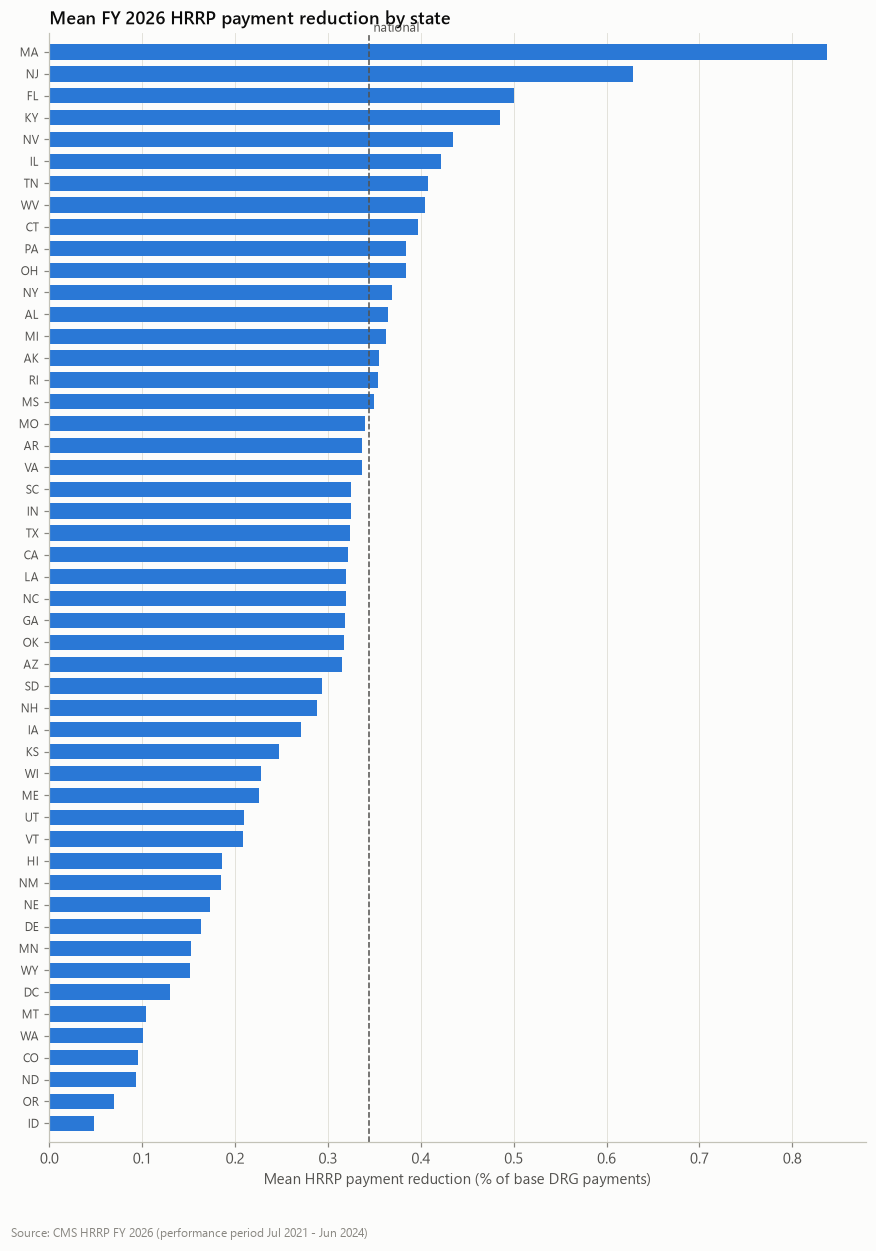

,STATE,hospitals,penalized_share,mean_reduction_pct
19,MA,53,0.8868,0.8372
30,NJ,61,0.9180,0.6284
9,FL,167,0.9281,0.5007
17,KY,59,0.8983,0.4853
32,NV,20,0.9000,0.4350


In [23]:
st = supp.groupby("STATE").agg(hospitals=("FACILITY_ID", "size"), penalized_share=("IS_PENALIZED", "mean"),
                               mean_reduction_pct=("PAYMENT_REDUCTION_PCT", "mean")).reset_index()
st.to_csv(TABLES / "state_payment_summary.csv", index=False)
viz.state_bars(st, "mean_reduction_pct", "Mean HRRP payment reduction (% of base DRG payments)",
               "Mean FY 2026 HRRP payment reduction by state", name="05_state_mean_payment_reduction",
               highlight_national=supp["PAYMENT_REDUCTION_PCT"].mean()); plt.show()
st.sort_values("mean_reduction_pct", ascending=False).head(5)

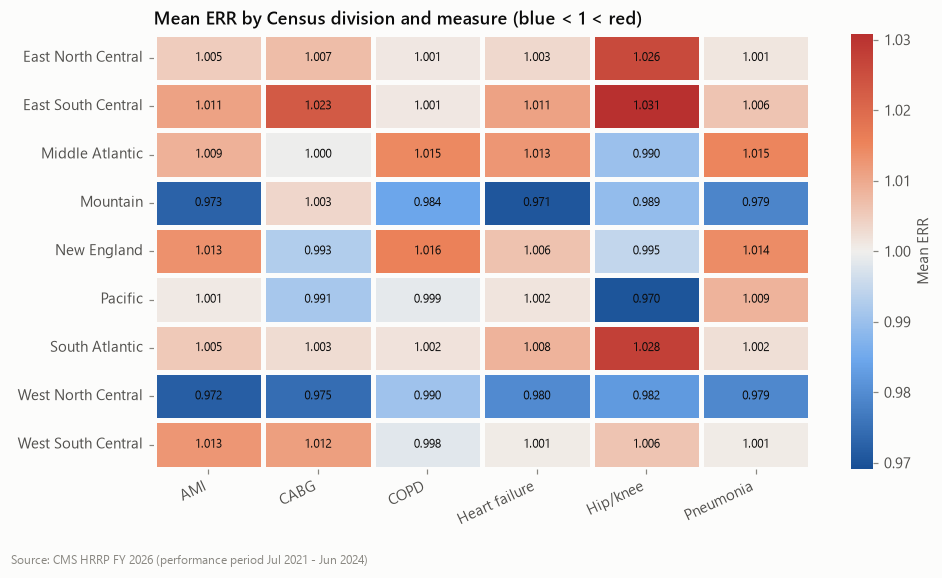

,MEASURE_CODE,n,welch_p_holm,kruskal_p_holm,epsilon_sq
0,AMI,1735,0.0000,0.0000,0.0296
1,CABG,878,0.1235,0.1107,0.0058
2,COPD,2322,0.0000,0.0000,0.0251
3,HF,2620,0.0000,0.0000,0.0276
4,HIP_KNEE,1446,0.0007,0.0007,0.0145
5,PN,2713,0.0000,0.0000,0.0215


In [24]:
pivot = df.pivot_table(index="CENSUS_REGION", columns="MEASURE_CODE", values="EXCESS_READMISSION_RATIO", aggfunc="mean")
viz.heatmap_region_measure(pivot, SHORT); plt.show()
h6 = sa.by_measure(df, sa.compare_k_groups, value="EXCESS_READMISSION_RATIO", group="CENSUS_REGION")
h6[["MEASURE_CODE", "n", "welch_p_holm", "kruskal_p_holm", "epsilon_sq"]]

**Interpretation.** Mean ERR differs significantly across Census divisions for every measure except CABG,
but effects are small (ε² ≤ 0.03). The **Mountain** and **West North Central** divisions have the lowest
ERRs on most medical measures. Hip/knee shows a different pattern (highest in the East North Central,
East South Central and South Atlantic divisions), another reason to analyse measures separately. States
with few hospitals have unstable means, so read the state bars together with the hospital counts in
`reports/tables/state_payment_summary.csv`.

## 9. Payment reduction distribution

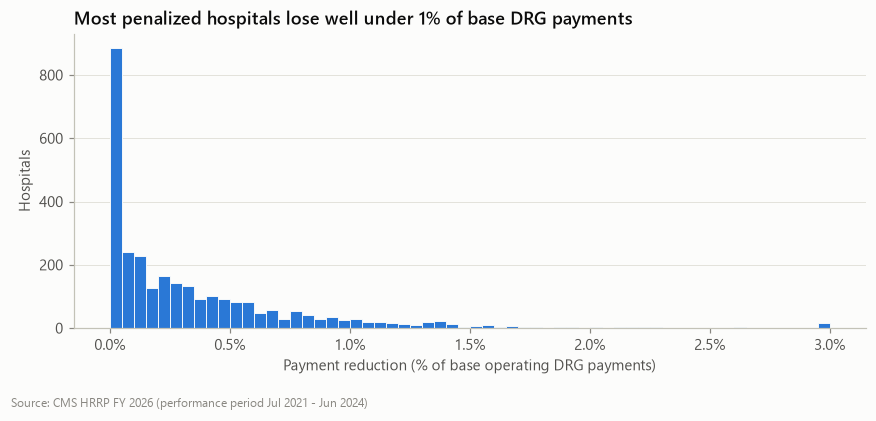

hospitals: 2,937 | penalized: 78.4% (95% CI 76.9%-79.8%)
median reduction 0.19% | mean 0.345% | at 3% cap: 15 hospitals


In [25]:
viz.histogram(supp["PAYMENT_REDUCTION_PCT"], "Payment reduction (% of base operating DRG payments)",
              "Most penalized hospitals lose well under 1% of base DRG payments", bins=np.arange(0, 3.05, 0.05),
              name="05b_payment_reduction_distribution", pct_axis=True); plt.show()
p = supp["PAYMENT_REDUCTION_PCT"]
lo, hi = sa.proportion_ci(int(supp.IS_PENALIZED.sum()), len(supp))
print(f"hospitals: {len(supp):,} | penalized: {supp.IS_PENALIZED.mean():.1%} (95% CI {lo:.1%}-{hi:.1%})")
print(f"median reduction {p.median():.2f}% | mean {p.mean():.3f}% | at 3% cap: {(p >= 3).sum()} hospitals")

**Interpretation.** Most hospitals in the Supplemental File receive some reduction, but the reductions are
small: the median is about 0.2% of base operating DRG payments, and only a handful of hospitals reach the 3% cap.
The file gives **percentages, not dollar amounts**, so this analysis does not estimate financial losses.

## 10. Penalty indicator by clinical measure
Denominator: hospitals with ≥25 eligible discharges for the measure (the CMS eligibility rule). Numerator: penalty indicator = Y.

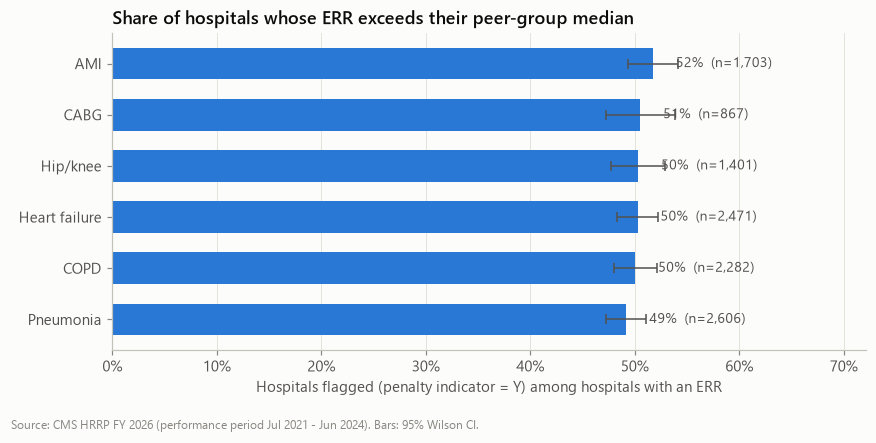

,MEASURE_CODE,n,y,rate,ci_low,ci_high,label
0,AMI,1703,881,0.5173,0.4936,0.5410,AMI
1,CABG,867,438,0.5052,0.4720,0.5384,CABG
2,COPD,2282,1142,0.5004,0.4799,0.5209,COPD
3,HF,2471,1242,0.5026,0.4829,0.5223,Heart failure
4,HIP_KNEE,1401,705,0.5032,0.4771,0.5293,Hip/knee
5,PN,2606,1282,0.4919,0.4728,0.5111,Pneumonia


In [26]:
el = mf[(mf.ELIGIBLE_DISCHARGES >= 25) & mf.PENALTY_INDICATOR.isin(["Y", "N"])]
pr = el.groupby("MEASURE_CODE").agg(n=("PENALTY_INDICATOR", "size"), y=("PENALTY_INDICATOR", lambda s: (s == "Y").sum())).reset_index()
pr["rate"] = pr.y / pr.n
pr[["ci_low", "ci_high"]] = [sa.proportion_ci(int(a), int(b)) for a, b in zip(pr.y, pr.n)]
pr["label"] = pr.MEASURE_CODE.map(SHORT)
pr.to_csv(TABLES / "penalty_rate_by_measure.csv", index=False)
viz.penalty_rate_by_measure(pr); plt.show(); pr

**Interpretation.** By definition, a hospital is flagged when its ERR exceeds its **peer-group median**, so
roughly half of eligible hospitals should be flagged on each measure. Rates close to 50% are expected and
do not, on their own, show that any one condition is "worse". What separates the measures is **how much
each contributes to the payment reduction** (DRG payment weight × size of the excess). That is the
Pareto analysis in `notebooks/02_pareto_analysis.ipynb`.

## 11. Summary of verified findings (associations only)
1. ERR is centred on 1.0 by design. Hip/knee and CABG vary most between hospitals.
2. **Teaching status**: no meaningful ERR difference on any measure (Holm-adjusted, robust to sensitivity analysis).
3. **Ownership**: proprietary hospitals have higher ERR on four measures (small effects), but this is not significant after adjustment.
4. **Large urban vs rural**: higher pneumonia and AMI ERR in large-urban hospitals (robust); the COPD result is fragile.
5. **Dual-eligible share**: associated with higher ERR, including after adjustment, but **not** with higher penalties. That is consistent with peer grouping.
6. **Penalty incidence** is strongly associated with hospital size, plausibly because of the ≥25-discharge eligibility rule.
7. Observable characteristics explain only ~6% of variation in mean ERR.

**Limitations:** one reporting period (no trends); aggregate hospital-level data; teaching status is a proxy;
current-snapshot hospital attributes vs. a 2021–2024 performance period; no cost data; unobserved confounding.